# Step 1: Data exploration

The exploratory analysis behind the interim report: how many articles each impression shows, how clicks, exposure and categories are distributed, how sparse the feedback is, and how noisy an article's click rate is at low exposure, which motivated the cold-start threshold. It explores the MIND-small train log; the temporal split and the features are built in step 2.

The analysis is kept as it was run for the interim report. Two findings were revised for the final report and are marked where they appear: **position bias** (section 3.2) and the **cold threshold** (before the threshold cells).

## Interim analysis: Part 2.2 — Impression, exposure and interaction dynamics

**Author:** Bryan  
**Purpose:** Analyze how users interact with news articles shown to them in impression slates. This notebook answers: *When the platform shows a user a set of articles, what actually happens?*

We cover four areas required by the interim report guideline:
1. **Impression Slate & Position Distribution** — How many articles are shown per impression, and how does CTR vary by position?
2. **Interaction Hierarchy & Funnel** — What does the impression-to-click pipeline look like? What are the conversion rates?
3. **Feedback Semantics** — How do we distinguish "shown but not clicked" (explicit negative) from "never shown" (unknown)?
4. **Click Behavior Patterns** — Distribution of clicks per impression, single-click vs multi-click behavior.


## 1. Setup & Data Loading

In [1]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import os
import warnings
warnings.filterwarnings('ignore')

# Set consistent plot styling
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

# Download MIND-small dataset via Kaggle
path = kagglehub.dataset_download("arashnic/mind-news-dataset")
print(f"Dataset downloaded to: {path}")
print(f"Contents: {os.listdir(path)}")


c:\Users\Bryan Ng\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset downloaded to: C:\Users\Bryan Ng\.cache\kagglehub\datasets\arashnic\mind-news-dataset\versions\2
Contents: ['MINDsmall_train', 'news.tsv']


In [2]:
# Load training data
train_path = os.path.join(path, "MINDsmall_train")
dev_path = os.path.join(path, "MINDsmall_dev")

BEHAVIOR_COLS = ['impression_id', 'user_id', 'time', 'history', 'impressions']
NEWS_COLS = ['news_id', 'category', 'subcategory', 'title', 'abstract', 'url', 'title_entities', 'abstract_entities']

# Load training behaviors and news
train_behaviors = pd.read_csv(os.path.join(train_path, "behaviors.tsv"), sep="\t", header=None, names=BEHAVIOR_COLS)

# Try loading dev set if available
has_dev = os.path.exists(os.path.join(dev_path, "behaviors.tsv"))
if has_dev:
    dev_behaviors = pd.read_csv(os.path.join(dev_path, "behaviors.tsv"), sep="\t", header=None, names=BEHAVIOR_COLS)
    train_behaviors['split'] = 'train'
    dev_behaviors['split'] = 'dev'
    behaviors = pd.concat([train_behaviors, dev_behaviors], ignore_index=True)
    print(f"Loaded train ({len(train_behaviors):,} rows) + dev ({len(dev_behaviors):,} rows)")
else:
    behaviors = train_behaviors.copy()
    behaviors['split'] = 'train'
    print(f"Loaded train only ({len(behaviors):,} rows). Dev set not found at {dev_path}")

# Load news metadata (combine train + dev if available)
news = pd.read_csv(os.path.join(train_path, "news.tsv"), sep="\t", header=None, names=NEWS_COLS)
if has_dev:
    dev_news = pd.read_csv(os.path.join(dev_path, "news.tsv"), sep="\t", header=None, names=NEWS_COLS)
    all_news = pd.concat([news, dev_news]).drop_duplicates(subset='news_id')
else:
    all_news = news.copy()

# Parse timestamps
behaviors['time'] = pd.to_datetime(behaviors['time'], format='%m/%d/%Y %I:%M:%S %p')

# Remove duplicates
behaviors.drop_duplicates(inplace=True)

print(f"\nTotal impression records: {len(behaviors):,}")
print(f"Unique users: {behaviors['user_id'].nunique():,}")
print(f"Unique news articles: {all_news['news_id'].nunique():,}")
print(f"Time range: {behaviors['time'].min()} to {behaviors['time'].max()}")
print(f"Users with no history: {behaviors['history'].isna().sum():,}")


Loaded train only (156,965 rows). Dev set not found at C:\Users\Bryan Ng\.cache\kagglehub\datasets\arashnic\mind-news-dataset\versions\2\MINDsmall_dev

Total impression records: 156,965
Unique users: 50,000
Unique news articles: 51,282
Time range: 2019-11-09 00:00:19 to 2019-11-14 23:59:13
Users with no history: 3,238


## 2. Parsing the Impression Data

Each row in `behaviors.tsv` has an `impressions` column that looks like:  
`N55689-1 N35729-0 N20678-0 N4321-0 N9876-0`

The suffix `-1` means the user **clicked** that article. The suffix `-0` means the article was **shown but not clicked**. 

We parse this into structured data so we can analyze position effects, click-through rates, and feedback types.


In [3]:
def parse_impression_row(impression_str):
    """Parse a single impression string into a list of (news_id, clicked, position) tuples."""
    if pd.isna(impression_str):
        return []
    items = impression_str.strip().split(' ')
    parsed = []
    for pos, item in enumerate(items):
        parts = item.rsplit('-', 1)
        news_id = parts[0]
        clicked = int(parts[1])
        parsed.append((news_id, clicked, pos + 1))  # 1-indexed position
    return parsed

# Parse all impressions
print("Parsing all impression records...")
behaviors['parsed_impressions'] = behaviors['impressions'].apply(parse_impression_row)

# Extract key counts per impression
behaviors['slate_length'] = behaviors['parsed_impressions'].apply(len)
behaviors['num_clicks'] = behaviors['parsed_impressions'].apply(lambda x: sum(1 for _, c, _ in x if c == 1))
behaviors['num_non_clicks'] = behaviors['slate_length'] - behaviors['num_clicks']

print(f"Done! Parsed {len(behaviors):,} impression records.")
print(f"\nSample parsed impression (first 5 items):")
print(behaviors['parsed_impressions'].iloc[0][:5])


Parsing all impression records...
Done! Parsed 156,965 impression records.

Sample parsed impression (first 5 items):
[('N55689', 1, 1), ('N35729', 0, 2)]


## 3. Impression Slate & Position Distribution

### 3.1 How many articles are shown per impression?

The "slate length" is the number of articles displayed to the user in a single impression. This tells us how much choice the user has each time they visit.


In [4]:
# Slate length statistics
print("=== Impression Slate Length Statistics ===")
print(f"Mean:   {behaviors['slate_length'].mean():.1f} articles per impression")
print(f"Median: {behaviors['slate_length'].median():.0f}")
print(f"Min:    {behaviors['slate_length'].min()}")
print(f"Max:    {behaviors['slate_length'].max()}")
print(f"Std:    {behaviors['slate_length'].std():.1f}")
print()

# Percentile breakdown
for p in [10, 25, 50, 75, 90, 95, 99]:
    print(f"  {p}th percentile: {behaviors['slate_length'].quantile(p/100):.0f} articles")


=== Impression Slate Length Statistics ===
Mean:   37.2 articles per impression
Median: 24
Min:    2
Max:    299
Std:    38.6

  10th percentile: 4 articles
  25th percentile: 10 articles
  50th percentile: 24 articles
  75th percentile: 51 articles
  90th percentile: 91 articles
  95th percentile: 118 articles
  99th percentile: 166 articles


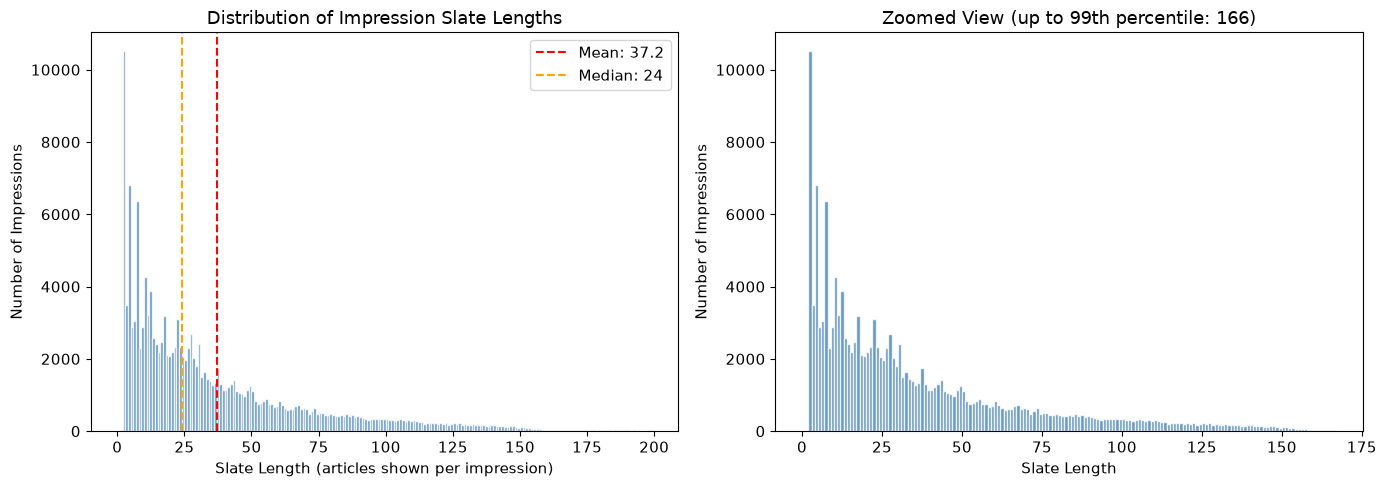

In [5]:
# Histogram of slate lengths
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: full distribution
axes[0].hist(behaviors['slate_length'], bins=range(0, min(behaviors['slate_length'].max() + 2, 200)),
             color='steelblue', edgecolor='white', alpha=0.8)
axes[0].set_xlabel('Slate Length (articles shown per impression)')
axes[0].set_ylabel('Number of Impressions')
axes[0].set_title('Distribution of Impression Slate Lengths')
axes[0].axvline(behaviors['slate_length'].mean(), color='red', linestyle='--',
                label=f"Mean: {behaviors['slate_length'].mean():.1f}")
axes[0].axvline(behaviors['slate_length'].median(), color='orange', linestyle='--',
                label=f"Median: {behaviors['slate_length'].median():.0f}")
axes[0].legend()

# Right: zoomed view on the common range
common = int(behaviors['slate_length'].quantile(0.99))
subset = behaviors[behaviors['slate_length'] <= common]
axes[1].hist(subset['slate_length'], bins=range(0, common + 2),
             color='steelblue', edgecolor='white', alpha=0.8)
axes[1].set_xlabel('Slate Length')
axes[1].set_ylabel('Number of Impressions')
axes[1].set_title(f'Zoomed View (up to 99th percentile: {common})')

plt.tight_layout()
plt.savefig('slate_length_distribution.png', bbox_inches='tight')
plt.show()


Slate length distribution:

The gap between the mean (37.2) and median (24) is the first important thing. When the mean is significantly higher than the median, it means the distribution is right-skewed — a large number of impressions show relatively few articles (the peak around 3–10 articles in your histogram), but a long tail of impressions show 100+ articles, dragging the average up. You can see this clearly in your chart: most of the mass is piled up on the left, with the tail stretching out to 299.

What this means practically: user experience varies enormously. Some users are shown just 2–4 articles (maybe a quick mobile glance), while others are shown 100+ (probably a desktop session where they scrolled extensively or refreshed multiple times). This has modeling implications — a user who clicked 1 out of 4 shown articles made a very different decision than a user who clicked 1 out of 150.

The spike pattern in the histogram (distinct peaks at certain values rather than a smooth curve) is also worth noting. It suggests the platform may use fixed slate sizes for certain display layouts — perhaps a mobile card layout shows batches of a specific size.

### 3.2 Click-Through Rate by Display Position

This is one of the most important analyses. If articles shown at position 1 get clicked far more than articles at position 20, it suggests **position bias** — users click what's at the top regardless of whether it's actually the best article for them.

This has direct implications for model training: a non-clicked article at position 25 might not be a true "negative" signal since the user may never have scrolled that far.


> **Revised for the final report: this is not position bias.** MIND shuffles the order of candidates within each impression, so the position in the log is not where the article appeared on screen. The decline below comes from slate length: every slate has a position 1, including short slates with high click rates (37% for 1–5 articles, section 7), while only long, low-CTR slates reach position 50. Rows at position 1 come from slates averaging 37 articles, rows at position 50 from slates averaging 91. Within slates of the same length the curve is flat: in slates of 100+ articles CTR is 1.9–2.2% at positions 1, 5, 10, 20, 50 and 90, and in slates of 20–29 articles it is 5.6% at positions 1–5 against 5.7% at positions 15–20. No model in this project uses position, and the interim report's position-debiasing proposal was dropped. The cells below are kept as they were run.

In [6]:
# Flatten all impressions into a single dataframe of (impression_id, news_id, clicked, position)
print("Building position-level dataframe")

rows = []
for idx, row in behaviors.iterrows():
    for news_id, clicked, position in row['parsed_impressions']:
        rows.append({
            'impression_id': row['impression_id'],
            'user_id': row['user_id'],
            'news_id': news_id,
            'clicked': clicked,
            'position': position
        })

impression_items = pd.DataFrame(rows)
print(f"Total article-impression pairs: {len(impression_items):,}")
print(f"  Clicked: {impression_items['clicked'].sum():,} ({impression_items['clicked'].mean():.2%})")
print(f"  Not clicked: {(impression_items['clicked'] == 0).sum():,}")


Building position-level dataframe
Total article-impression pairs: 5,843,444
  Clicked: 236,344 (4.04%)
  Not clicked: 5,607,100


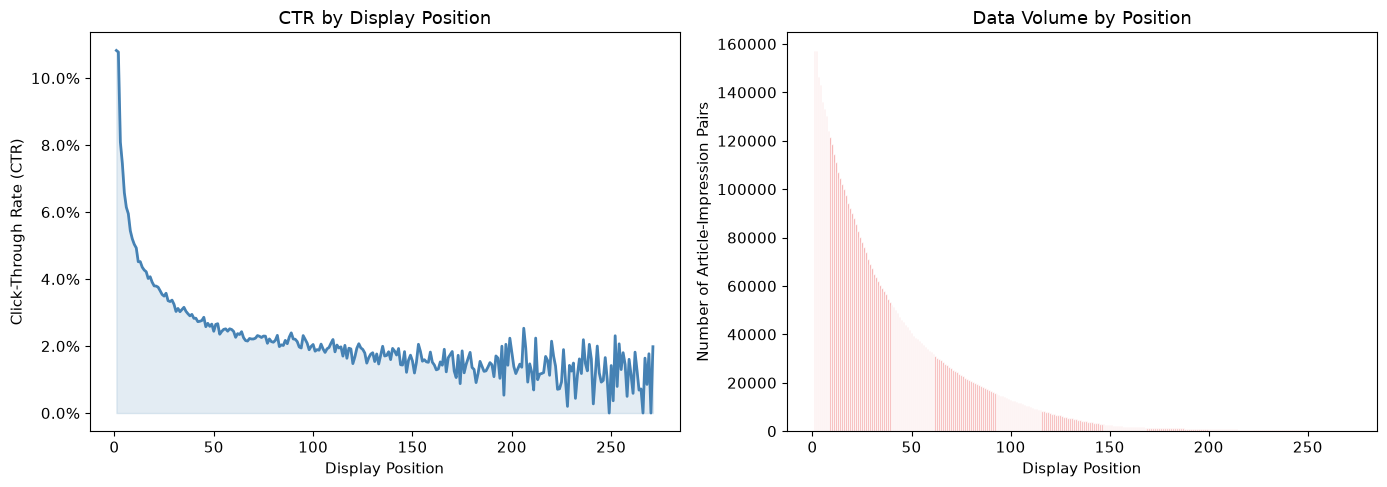


=== CTR by Position (Top 15) ===
  Position  1: CTR = 10.82%  (n = 156,965)
  Position  2: CTR = 10.78%  (n = 156,965)
  Position  3: CTR = 8.09%  (n = 146,456)
  Position  4: CTR = 7.45%  (n = 142,952)
  Position  5: CTR = 6.58%  (n = 136,143)
  Position  6: CTR = 6.14%  (n = 133,254)
  Position  7: CTR = 5.95%  (n = 130,201)
  Position  8: CTR = 5.44%  (n = 123,836)
  Position  9: CTR = 5.20%  (n = 121,522)
  Position 10: CTR = 5.04%  (n = 118,644)
  Position 11: CTR = 4.93%  (n = 114,365)
  Position 12: CTR = 4.52%  (n = 111,164)
  Position 13: CTR = 4.52%  (n = 107,288)
  Position 14: CTR = 4.36%  (n = 104,713)
  Position 15: CTR = 4.27%  (n = 102,301)


In [7]:
# CTR by position
ctr_by_pos = impression_items.groupby('position').agg(
    total=('clicked', 'count'),
    clicks=('clicked', 'sum')
).reset_index()
ctr_by_pos['ctr'] = ctr_by_pos['clicks'] / ctr_by_pos['total']

# Only plot positions with enough data (at least 100 impressions)
ctr_by_pos_filtered = ctr_by_pos[ctr_by_pos['total'] >= 100]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: CTR by position
axes[0].plot(ctr_by_pos_filtered['position'], ctr_by_pos_filtered['ctr'],
             color='steelblue', linewidth=2)
axes[0].fill_between(ctr_by_pos_filtered['position'], ctr_by_pos_filtered['ctr'],
                      alpha=0.15, color='steelblue')
axes[0].set_xlabel('Display Position')
axes[0].set_ylabel('Click-Through Rate (CTR)')
axes[0].set_title('CTR by Display Position')
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

# Right: volume by position (how many impressions have each position)
axes[1].bar(ctr_by_pos_filtered['position'], ctr_by_pos_filtered['total'],
            color='lightcoral', edgecolor='white', alpha=0.8)
axes[1].set_xlabel('Display Position')
axes[1].set_ylabel('Number of Article-Impression Pairs')
axes[1].set_title('Data Volume by Position')

plt.tight_layout()
plt.savefig('ctr_by_position.png', bbox_inches='tight')
plt.show()

# Print first 15 positions
print("\n=== CTR by Position (Top 15) ===")
for _, row in ctr_by_pos_filtered.head(15).iterrows():
    print(f"  Position {int(row['position']):>2d}: CTR = {row['ctr']:.2%}  (n = {int(row['total']):,})")


In [8]:
# Compare top-3 positions vs rest
top3 = impression_items[impression_items['position'] <= 3]
rest = impression_items[impression_items['position'] > 3]

print("=== Position Bias Summary ===")
print(f"Positions 1-3:  CTR = {top3['clicked'].mean():.2%}  (n = {len(top3):,})")
print(f"Positions 4+:   CTR = {rest['clicked'].mean():.2%}  (n = {len(rest):,})")
if rest['clicked'].mean() > 0:
    print(f"Ratio: Top-3 CTR is {top3['clicked'].mean() / rest['clicked'].mean():.1f}x higher than the rest")
print()
print("This suggests position bias — articles shown higher get clicked more,")
print("which is partly due to user scrolling behavior, not just article quality.")


=== Position Bias Summary ===
Positions 1-3:  CTR = 9.94%  (n = 460,386)
Positions 4+:   CTR = 3.54%  (n = 5,383,058)
Ratio: Top-3 CTR is 2.8x higher than the rest

This suggests position bias — articles shown higher get clicked more,
which is partly due to user scrolling behavior, not just article quality.


Position 1 and 2 have nearly identical CTR (~10.8%), which is interesting. It suggests articles in the first two slots get roughly equal visual treatment — possibly displayed side-by-side or both visible without scrolling. Then position 3 drops to 8.09%, and from there it's a steady decline.

The shape of your CTR curve is a textbook position bias pattern: a steep drop-off in the first ~20 positions (10.8% → ~3%), then it flattens out around 1.5–2% for everything beyond position 50. The flattening means that once you're far enough down the list, position barely matters anymore — the users who scroll that far are probably browsing deliberately and click at a roughly constant rate regardless of exact position.

The 2.8x ratio between top-3 and the rest is meaningful but not extreme. It tells you that position matters, but it doesn't completely dominate — there's still genuine preference signal in the clicks. If the ratio were 10x or higher, you'd worry that almost all clicks are position-driven rather than preference-driven.

The volume chart on the right confirms what the slate length distribution tells you: most impressions only have articles at low positions. By position 50, the data volume has dropped dramatically, which means CTR estimates at higher positions are based on fewer observations and are noisier (hence the jaggedness in the CTR line beyond position ~100).

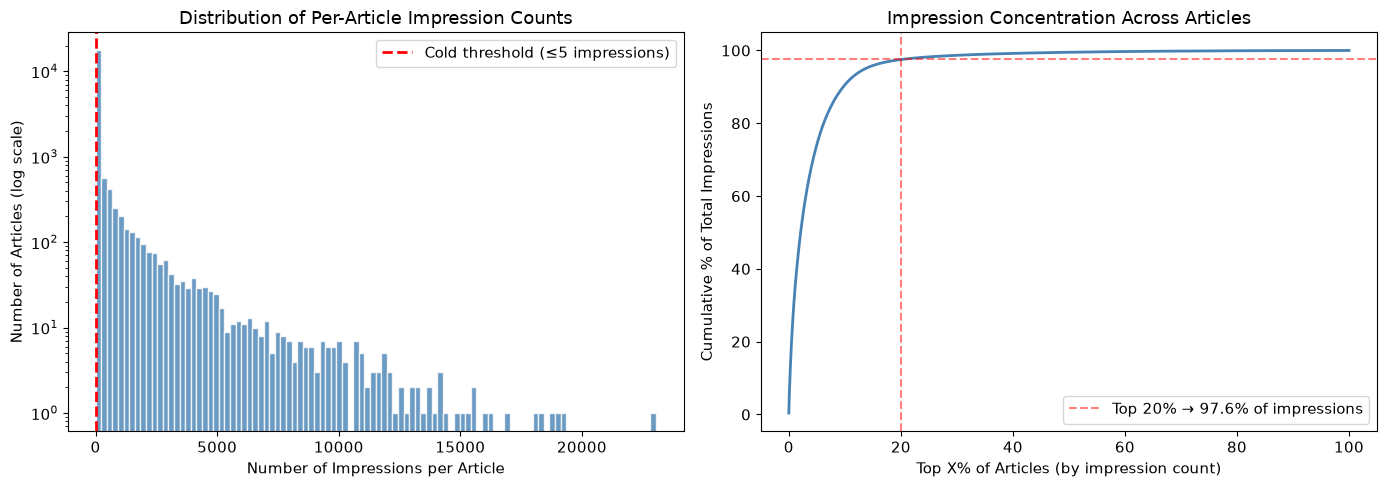

In [9]:
article_impressions = impression_items.groupby('news_id').size().reset_index(name='impression_count')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: distribution of impression counts per article (log scale)
axes[0].hist(article_impressions['impression_count'], bins=100,
             color='steelblue', edgecolor='white', alpha=0.8)
axes[0].set_yscale('log')
axes[0].axvline(5, color='red', linestyle='--', linewidth=2, label='Cold threshold (≤5 impressions)')
axes[0].set_xlabel('Number of Impressions per Article')
axes[0].set_ylabel('Number of Articles (log scale)')
axes[0].set_title('Distribution of Per-Article Impression Counts')
axes[0].legend()

# Right: cumulative share of impressions (to show concentration)
sorted_counts = article_impressions['impression_count'].sort_values(ascending=False).values
cumulative_share = np.cumsum(sorted_counts) / sorted_counts.sum()
article_pct = np.arange(1, len(sorted_counts) + 1) / len(sorted_counts) * 100

axes[1].plot(article_pct, cumulative_share * 100, color='steelblue', linewidth=2)
axes[1].axhline(97.6, color='red', linestyle='--', alpha=0.5, label='Top 20% → 97.6% of impressions')
axes[1].axvline(20, color='red', linestyle='--', alpha=0.5)
axes[1].set_xlabel('Top X% of Articles (by impression count)')
axes[1].set_ylabel('Cumulative % of Total Impressions')
axes[1].set_title('Impression Concentration Across Articles')
axes[1].legend()

plt.tight_layout()
plt.savefig('exposure_concentration.png', bbox_inches='tight')
plt.show()

## 4. Interaction Hierarchy & Funnel

MIND only has binary click/no-click interactions (unlike e-commerce datasets which have click → cart → purchase). But we can still analyze the funnel:

**Impression** → **Exposure** (article appears in slate) → **Click** (user clicks)

We can also look at the ratio of positive to negative signals, which matters for model training.


In [10]:
# Overall funnel
total_impressions = len(behaviors)
total_exposures = len(impression_items)
total_clicks = int(impression_items['clicked'].sum())
total_non_clicks = int((impression_items['clicked'] == 0).sum())

print("=== Impression → Click Funnel ===")
print(f"Total impression events:        {total_impressions:>10,}")
print(f"Total article exposures:        {total_exposures:>10,}  (avg {total_exposures/total_impressions:.1f} articles per impression)")
print(f"Total clicks:                   {total_clicks:>10,}")
print(f"Total shown-but-not-clicked:    {total_non_clicks:>10,}")
print()
print(f"Overall CTR:                    {total_clicks / total_exposures:.2%}")
print(f"Positive:Negative ratio:        1 : {total_non_clicks / max(total_clicks, 1):.1f}")
print()
print(f"For every article a user clicks, ~{total_non_clicks / max(total_clicks, 1):.0f} articles")
print("were shown but ignored. This heavy class imbalance is important")
print("for model training — naive training would be dominated by negatives.")


=== Impression → Click Funnel ===
Total impression events:           156,965
Total article exposures:         5,843,444  (avg 37.2 articles per impression)
Total clicks:                      236,344
Total shown-but-not-clicked:     5,607,100

Overall CTR:                    4.04%
Positive:Negative ratio:        1 : 23.7

For every article a user clicks, ~24 articles
were shown but ignored. This heavy class imbalance is important
for model training — naive training would be dominated by negatives.


In [11]:
# Impressions with zero clicks vs at least one click
zero_click = behaviors[behaviors['num_clicks'] == 0]
has_click = behaviors[behaviors['num_clicks'] > 0]

print("=== Zero-Click vs Active Impressions ===")
print(f"Impressions with 0 clicks: {len(zero_click):,} ({len(zero_click)/len(behaviors):.1%})")
print(f"Impressions with 1+ clicks: {len(has_click):,} ({len(has_click)/len(behaviors):.1%})")
print()
if len(zero_click) > 0:
    print(f"Average slate length (zero-click): {zero_click['slate_length'].mean():.1f}")
print(f"Average slate length (has clicks): {has_click['slate_length'].mean():.1f}")
print()
print("Zero-click impressions may represent cases where the user glanced")
print("at the feed but nothing caught their interest, or they left quickly.")


=== Zero-Click vs Active Impressions ===
Impressions with 0 clicks: 0 (0.0%)
Impressions with 1+ clicks: 156,965 (100.0%)

Average slate length (has clicks): 37.2

Zero-click impressions may represent cases where the user glanced
at the feed but nothing caught their interest, or they left quickly.


## 5. Click Behavior Patterns

### 5.1 How many articles do users click per impression?

This tells us whether users typically read just one article or browse through several.


In [12]:
# Distribution of clicks per impression (only for impressions with at least 1 click)
click_counts = has_click['num_clicks']

print("=== Clicks per Impression (among impressions with >= 1 click) ===")
print(f"Mean:   {click_counts.mean():.2f}")
print(f"Median: {click_counts.median():.0f}")
print(f"Max:    {click_counts.max()}")
print()

# Breakdown
for n_clicks in range(1, min(8, int(click_counts.max()) + 1)):
    count = int((click_counts == n_clicks).sum())
    pct = count / len(click_counts)
    print(f"  {n_clicks} click(s): {count:>6,} impressions ({pct:.1%})")

more = int((click_counts >= 8).sum())
if more > 0:
    print(f"  8+ clicks: {more:>6,} impressions ({more/len(click_counts):.1%})")


=== Clicks per Impression (among impressions with >= 1 click) ===
Mean:   1.51
Median: 1
Max:    35

  1 click(s): 113,888 impressions (72.6%)
  2 click(s): 25,571 impressions (16.3%)
  3 click(s):  9,263 impressions (5.9%)
  4 click(s):  3,975 impressions (2.5%)
  5 click(s):  1,957 impressions (1.2%)
  6 click(s):    942 impressions (0.6%)
  7 click(s):    515 impressions (0.3%)
  8+ clicks:    854 impressions (0.5%)


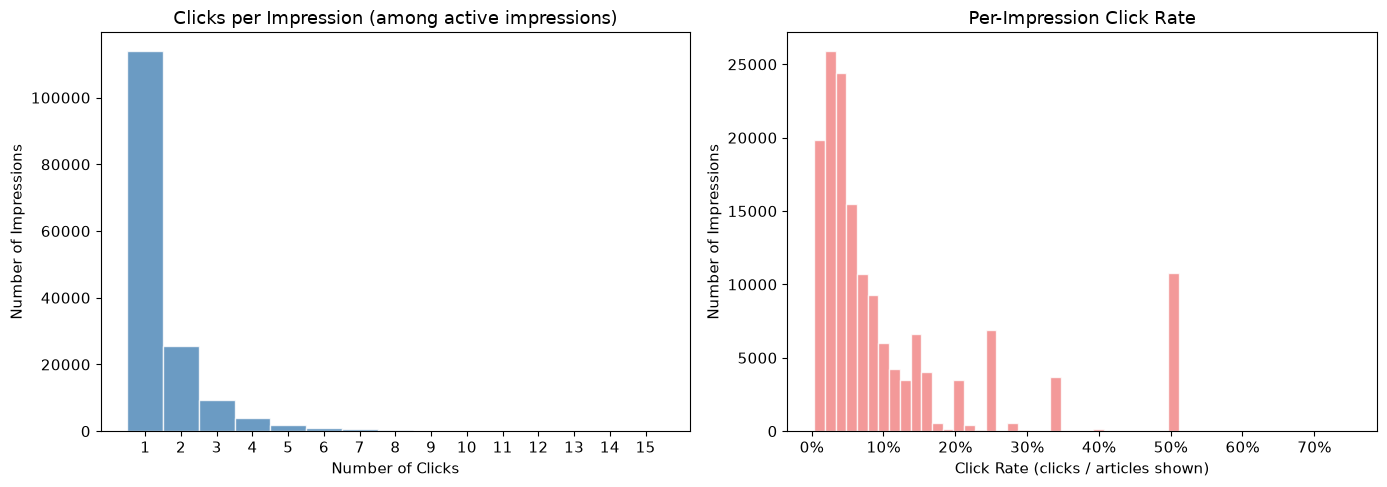

In [13]:
# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: clicks per impression histogram
max_show = min(15, int(click_counts.max()))
axes[0].hist(click_counts[click_counts <= max_show], bins=range(1, max_show + 2),
             color='steelblue', edgecolor='white', alpha=0.8, align='left')
axes[0].set_xlabel('Number of Clicks')
axes[0].set_ylabel('Number of Impressions')
axes[0].set_title('Clicks per Impression (among active impressions)')
axes[0].set_xticks(range(1, max_show + 1))

# Right: clicks as a fraction of slate length
has_click_copy = has_click.copy()
has_click_copy['click_rate'] = has_click_copy['num_clicks'] / has_click_copy['slate_length']
axes[1].hist(has_click_copy['click_rate'], bins=50,
             color='lightcoral', edgecolor='white', alpha=0.8)
axes[1].set_xlabel('Click Rate (clicks / articles shown)')
axes[1].set_ylabel('Number of Impressions')
axes[1].set_title('Per-Impression Click Rate')
axes[1].xaxis.set_major_formatter(mticker.PercentFormatter(1.0))

plt.tight_layout()
plt.savefig('clicks_per_impression.png', bbox_inches='tight')
plt.show()


Every single impression has at least 1 click — zero out of 156,965 impressions have zero clicks. This means the dataset was pre-filtered to only include impressions where the user clicked something. This is a data construction choice, not natural user behavior (in reality, many users would glance at the feed and leave without clicking). It's worth noting because it means your models will never see the "user wasn't interested in anything" scenario during training.

Clicks per impression: The distribution is extremely concentrated — 72.6% of impressions have exactly 1 click, and 95% have 3 or fewer. The spike at 50% click rate in the right histogram corresponds to the short slates (if you're shown 2 articles and click 1, that's a 50% rate). The typical user browses the feed, clicks one article, and moves on.

## 6. Feedback Semantics: Explicit Negatives vs Unknown

This is a critical conceptual distinction the course emphasizes. In the MIND dataset, we have **three types of user-item relationships**:

1. **Clicked (Positive):** The article was shown AND the user clicked it → strong positive signal.
2. **Shown but not clicked (Explicit Negative):** The article was displayed in the impression slate but the user did NOT click it → the user *saw* it (or at least had the opportunity to see it) and chose not to engage.
3. **Never shown (Unknown/Unobserved):** The article was never part of this user's impression slate → we have NO information about whether the user would have liked it.

The distinction between (2) and (3) matters enormously for training:
- **Shown-but-not-clicked** items are more informative negatives than random items. The platform's algorithm already thought these were relevant enough to show.
- **Never-shown** items are a mix of irrelevant items AND potentially good items the platform just didn't surface.
- Using random negatives (type 3) instead of impression negatives (type 2) during training can lead to a model that learns easy distinctions rather than hard ones.


In [14]:
# Quantify the three feedback types
total_articles = len(all_news)
total_users = behaviors['user_id'].nunique()

# Articles that appeared in at least one impression
articles_in_impressions = impression_items['news_id'].nunique()
articles_clicked = impression_items[impression_items['clicked'] == 1]['news_id'].nunique()

# Per-user perspective: average articles exposed vs clicked vs never shown
user_exposure = impression_items.groupby('user_id').agg(
    articles_exposed=('news_id', 'nunique'),
    articles_clicked=('clicked', 'sum')
).reset_index()
user_exposure['articles_never_shown'] = total_articles - user_exposure['articles_exposed']

print("=== Feedback Type Breakdown (Dataset Level) ===")
print(f"Total unique articles in dataset: {total_articles:,}")
print(f"Articles in at least one impression: {articles_in_impressions:,}")
print(f"Articles clicked at least once: {articles_clicked:,}")
print()
print("=== Per-User Averages ===")
print(f"Avg articles exposed to a user:     {user_exposure['articles_exposed'].mean():>8,.1f}")
print(f"Avg articles clicked by a user:     {user_exposure['articles_clicked'].mean():>8,.1f}")
print(f"Avg articles never shown to a user: {user_exposure['articles_never_shown'].mean():>8,.1f}")
print()
print(f"On average, a user sees {user_exposure['articles_exposed'].mean() / total_articles:.2%} of all articles")
print(f"and clicks on {user_exposure['articles_clicked'].mean() / total_articles:.4%} of all articles.")
print()
print("For any given user-article pair, the overwhelming likelihood is that")
print("the user was never shown the article at all (Unknown). The small set")
print("of impression negatives (shown but not clicked) are far more informative.")


=== Feedback Type Breakdown (Dataset Level) ===
Total unique articles in dataset: 51,282
Articles in at least one impression: 20,288
Articles clicked at least once: 7,713

=== Per-User Averages ===
Avg articles exposed to a user:         99.8
Avg articles clicked by a user:          4.7
Avg articles never shown to a user: 51,182.2

On average, a user sees 0.19% of all articles
and clicks on 0.0092% of all articles.

For any given user-article pair, the overwhelming likelihood is that
the user was never shown the article at all (Unknown). The small set
of impression negatives (shown but not clicked) are far more informative.


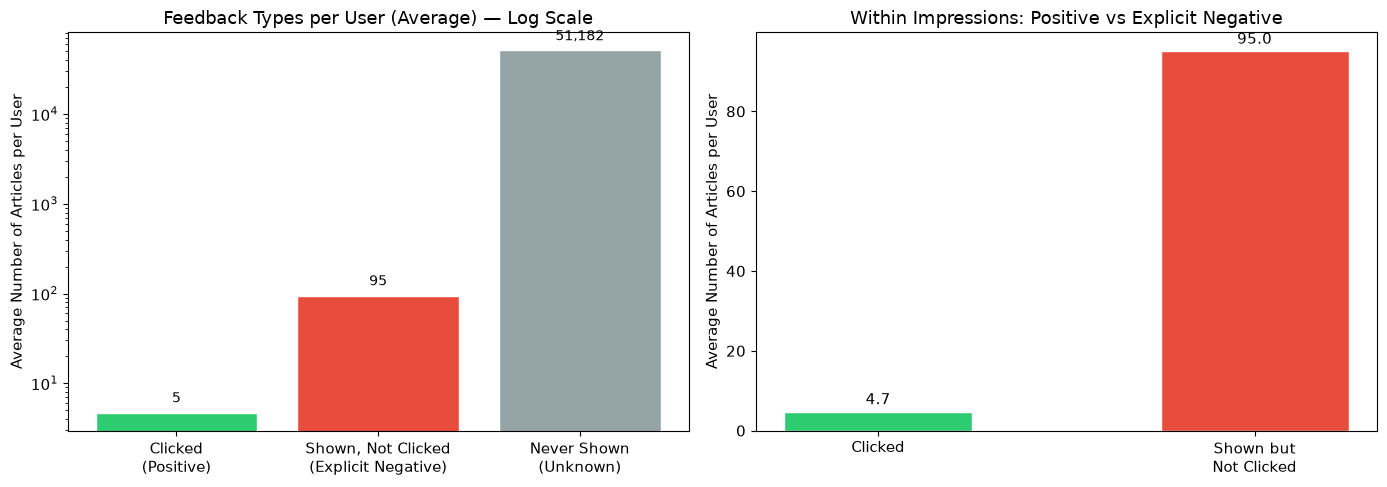

In [15]:
# Visualize the three feedback types (per-user perspective)
avg_exposed = user_exposure['articles_exposed'].mean()
avg_clicked = user_exposure['articles_clicked'].mean()
avg_not_shown = user_exposure['articles_never_shown'].mean()
avg_shown_not_clicked = avg_exposed - avg_clicked

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: bar chart of average feedback types per user (log scale)
labels = ['Clicked\n(Positive)', 'Shown, Not Clicked\n(Explicit Negative)', 'Never Shown\n(Unknown)']
values = [avg_clicked, avg_shown_not_clicked, avg_not_shown]
colors = ['#2ecc71', '#e74c3c', '#95a5a6']
bars = axes[0].bar(labels, values, color=colors, edgecolor='white')
axes[0].set_ylabel('Average Number of Articles per User')
axes[0].set_title('Feedback Types per User (Average) — Log Scale')
axes[0].set_yscale('log')
for bar, val in zip(bars, values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.3,
                 f'{val:,.0f}', ha='center', fontsize=10)

# Right: zoom into impression-level data only
labels2 = ['Clicked', 'Shown but\nNot Clicked']
values2 = [avg_clicked, avg_shown_not_clicked]
colors2 = ['#2ecc71', '#e74c3c']
bars2 = axes[1].bar(labels2, values2, color=colors2, edgecolor='white', width=0.5)
axes[1].set_ylabel('Average Number of Articles per User')
axes[1].set_title('Within Impressions: Positive vs Explicit Negative')
for bar, val in zip(bars2, values2):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(values2)*0.02,
                 f'{val:,.1f}', ha='center', fontsize=11)

plt.tight_layout()
plt.savefig('feedback_semantics.png', bbox_inches='tight')
plt.show()


Feedback semantics: The log-scale chart makes the magnitude difference visceral. A user clicks ~5 articles, is shown-but-doesn't-click ~95 articles, and never sees ~51,182 articles. Each user is exposed to just 0.19% of the full article catalog. This is extremely sparse — and it means that randomly sampling negatives from the full catalog gives you "easy" negatives (a user interested in sports news being paired with an auto finance article they'd obviously never click), while the impression negatives are "hard" negatives (articles the platform's algorithm thought were relevant enough to display).

## 7. Does Slate Length Affect Click Behavior?

Do longer slates (more articles shown) dilute attention, or do they give users more chances to find something interesting?


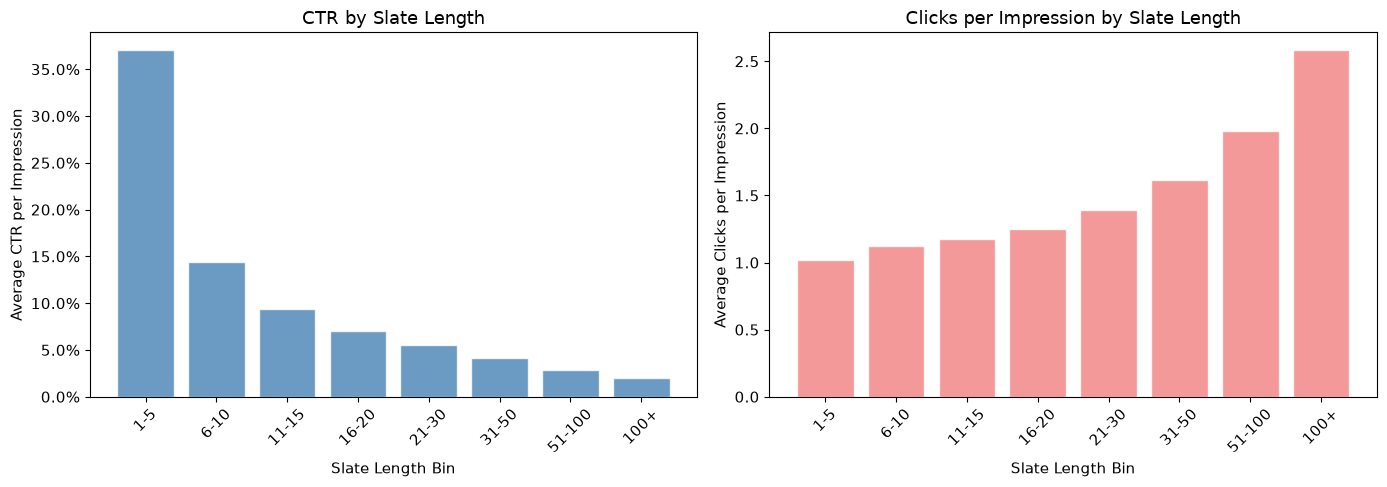

=== CTR by Slate Length ===
  Slate      1-5: avg CTR = 37.09%, avg clicks = 1.02, n = 23,711
  Slate     6-10: avg CTR = 14.45%, avg clicks = 1.12, n = 18,889
  Slate    11-15: avg CTR = 9.33%, avg clicks = 1.18, n = 14,248
  Slate    16-20: avg CTR = 7.04%, avg clicks = 1.25, n = 12,019
  Slate    21-30: avg CTR = 5.54%, avg clicks = 1.39, n = 23,029
  Slate    31-50: avg CTR = 4.09%, avg clicks = 1.61, n = 25,545
  Slate   51-100: avg CTR = 2.85%, avg clicks = 1.98, n = 26,855
  Slate     100+: avg CTR = 1.98%, avg clicks = 2.59, n = 12,669


In [16]:
# CTR by slate length (binned for clarity)
behaviors_active = behaviors.copy()
behaviors_active['ctr'] = behaviors_active['num_clicks'] / behaviors_active['slate_length']

# Bin slate lengths
bins = [0, 5, 10, 15, 20, 30, 50, 100, float('inf')]
labels_bins = ['1-5', '6-10', '11-15', '16-20', '21-30', '31-50', '51-100', '100+']
behaviors_active['slate_bin'] = pd.cut(behaviors_active['slate_length'], bins=bins, labels=labels_bins)

slate_stats = behaviors_active.groupby('slate_bin', observed=True).agg(
    count=('ctr', 'count'),
    avg_ctr=('ctr', 'mean'),
    avg_clicks=('num_clicks', 'mean')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(slate_stats['slate_bin'].astype(str), slate_stats['avg_ctr'],
            color='steelblue', edgecolor='white', alpha=0.8)
axes[0].set_xlabel('Slate Length Bin')
axes[0].set_ylabel('Average CTR per Impression')
axes[0].set_title('CTR by Slate Length')
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[0].tick_params(axis='x', rotation=45)

axes[1].bar(slate_stats['slate_bin'].astype(str), slate_stats['avg_clicks'],
            color='lightcoral', edgecolor='white', alpha=0.8)
axes[1].set_xlabel('Slate Length Bin')
axes[1].set_ylabel('Average Clicks per Impression')
axes[1].set_title('Clicks per Impression by Slate Length')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('ctr_by_slate_length.png', bbox_inches='tight')
plt.show()

print("=== CTR by Slate Length ===")
for _, row in slate_stats.iterrows():
    print(f"  Slate {str(row['slate_bin']):>8s}: avg CTR = {row['avg_ctr']:.2%}, avg clicks = {row['avg_clicks']:.2f}, n = {int(row['count']):,}")


There's a clear inverse relationship: CTR drops from 37% for tiny slates (1–5 articles) to just 2% for large slates (100+). But in the right panel, absolute clicks increase with slate length (1.02 clicks for tiny slates vs. 2.59 for 100+ slates). This tells you that longer sessions mean more engagement overall, but the proportion of what gets clicked drops because there's so much more to ignore. This has a practical modeling implication: a model's impression-level CTR will look artificially good on short slates and worse on long ones, so evaluating across slate lengths matters.

## 8. What Categories Get Clicked vs Ignored?

This shows whether certain news categories are more "clickable" than others, which can inform feature engineering and model interpretation.


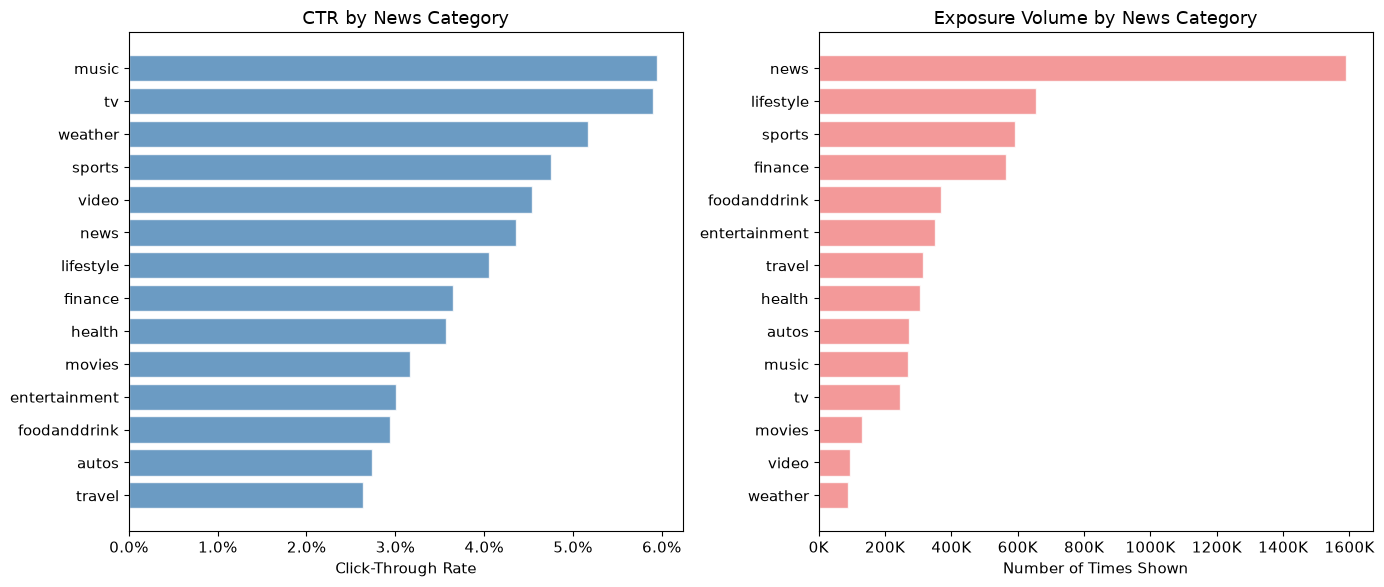


=== CTR by Category (sorted by CTR) ===
                 music: CTR = 5.94%  (shown  269,008x, clicked 15,988x)
                    tv: CTR = 5.90%  (shown  246,462x, clicked 14,544x)
               weather: CTR = 5.17%  (shown   88,646x, clicked  4,582x)
                sports: CTR = 4.76%  (shown  592,226x, clicked 28,181x)
                 video: CTR = 4.55%  (shown   93,744x, clicked  4,262x)
                  news: CTR = 4.36%  (shown 1,591,038x, clicked 69,408x)
             lifestyle: CTR = 4.06%  (shown  655,440x, clicked 26,584x)
               finance: CTR = 3.65%  (shown  564,671x, clicked 20,597x)
                health: CTR = 3.57%  (shown  304,088x, clicked 10,863x)
                movies: CTR = 3.17%  (shown  132,091x, clicked  4,186x)
         entertainment: CTR = 3.01%  (shown  349,930x, clicked 10,530x)
          foodanddrink: CTR = 2.95%  (shown  369,382x, clicked 10,883x)
                 autos: CTR = 2.74%  (shown  271,426x, clicked  7,428x)
                travel

In [17]:
# Merge impression items with news metadata
impression_with_news = impression_items.merge(
    all_news[['news_id', 'category', 'subcategory']],
    on='news_id',
    how='left'
)

# CTR by category
cat_stats = impression_with_news.groupby('category').agg(
    total_shown=('clicked', 'count'),
    total_clicked=('clicked', 'sum')
).reset_index()
cat_stats['ctr'] = cat_stats['total_clicked'] / cat_stats['total_shown']
cat_stats = cat_stats.sort_values('ctr', ascending=True)

# Only show categories with meaningful volume
cat_stats_filtered = cat_stats[cat_stats['total_shown'] >= 1000]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(cat_stats_filtered['category'], cat_stats_filtered['ctr'],
             color='steelblue', edgecolor='white', alpha=0.8)
axes[0].set_xlabel('Click-Through Rate')
axes[0].set_title('CTR by News Category')
axes[0].xaxis.set_major_formatter(mticker.PercentFormatter(1.0))

cat_vol = cat_stats_filtered.sort_values('total_shown', ascending=True)
axes[1].barh(cat_vol['category'], cat_vol['total_shown'],
             color='lightcoral', edgecolor='white', alpha=0.8)
axes[1].set_xlabel('Number of Times Shown')
axes[1].set_title('Exposure Volume by News Category')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'{x/1000:.0f}K'))

plt.tight_layout()
plt.savefig('ctr_by_category.png', bbox_inches='tight')
plt.show()

print("\n=== CTR by Category (sorted by CTR) ===")
for _, row in cat_stats_filtered.sort_values('ctr', ascending=False).iterrows():
    print(f"  {row['category']:>20s}: CTR = {row['ctr']:.2%}  (shown {int(row['total_shown']):>8,}x, clicked {int(row['total_clicked']):>6,}x)")


The interesting finding is the disconnect between volume and engagement. "News" dominates exposure volume (1.59M, more than 2x any other category) but sits mid-table on CTR (4.36%). Meanwhile "music" and "tv" have the highest CTR (~6%) but relatively low exposure. This suggests the platform shows a lot of general news by default, but users are disproportionately drawn to entertainment-oriented content. "Travel" and "autos" are the least engaging categories — lots of exposure, low CTR.

In [18]:
# Entity coverage: % of articles with at least one entity
has_entity = all_news.apply(
    lambda row: (pd.notna(row['title_entities']) and row['title_entities'] != '[]') or 
                (pd.notna(row['abstract_entities']) and row['abstract_entities'] != '[]'), 
    axis=1
)
print(f"Articles with ≥1 entity: {has_entity.mean():.1%}")

Articles with ≥1 entity: 86.7%


In [19]:
has_abstract = all_news['abstract'].notna() & (all_news['abstract'].str.strip() != '')
print(f"Articles with abstract: {has_abstract.mean():.1%}")

Articles with abstract: 94.8%


In [20]:
# Load entity embeddings
entity_emb = pd.read_csv(os.path.join(train_path, 'entity_embedding.vec'), 
                          sep='\t', header=None)
entity_ids_with_embeddings = set(entity_emb[0].values)

# Parse all entity IDs from news articles and check coverage
# (this depends on how the entity JSON is structured)

In [21]:
import json

# Parse all unique entity IDs from news articles
all_entity_ids = set()
for col in ['title_entities', 'abstract_entities']:
    for val in all_news[col].dropna():
        if val == '[]':
            continue
        try:
            entities = json.loads(val)
            for e in entities:
                all_entity_ids.add(e['WikidataId'])
        except:
            continue

print(f"Unique entities referenced in articles: {len(all_entity_ids)}")

# Check how many have embeddings
covered = all_entity_ids.intersection(entity_ids_with_embeddings)
print(f"Entities with KG embeddings: {len(covered)} / {len(all_entity_ids)} ({len(covered)/len(all_entity_ids):.1%})")

Unique entities referenced in articles: 27759
Entities with KG embeddings: 26902 / 27759 (96.9%)


In [22]:
# Check a sample of URLs for embedded dates
print(all_news['url'].head(20).tolist())

['https://assets.msn.com/labs/mind/AAGH0ET.html', 'https://assets.msn.com/labs/mind/AAB19MK.html', 'https://assets.msn.com/labs/mind/AAJgNsz.html', 'https://assets.msn.com/labs/mind/AACk2N6.html', 'https://assets.msn.com/labs/mind/AAAKEkt.html', 'https://assets.msn.com/labs/mind/AAJ4lap.html', 'https://assets.msn.com/labs/mind/AAJwoxD.html', 'https://assets.msn.com/labs/mind/AAJ43pw.html', 'https://assets.msn.com/labs/mind/AACHUn8.html', 'https://assets.msn.com/labs/mind/AAlErhA.html', 'https://assets.msn.com/labs/mind/AABDHTv.html', 'https://assets.msn.com/labs/mind/AADKhPQ.html', 'https://assets.msn.com/labs/mind/AABqkFQ.html', 'https://assets.msn.com/labs/mind/AAJaBOM.html', 'https://assets.msn.com/labs/mind/AAJwfO8.html', 'https://assets.msn.com/labs/mind/AAEBVOU.html', 'https://assets.msn.com/labs/mind/AABv6WU.html', 'https://assets.msn.com/labs/mind/AAJfTqo.html', 'https://assets.msn.com/labs/mind/AAGZhlc.html', 'https://assets.msn.com/labs/mind/AAISxPW.html']


### Cold-start threshold (interim analysis)

> **Revised for the final report.** The cells below count an article's *total* impressions over the whole six days and try thresholds of ≤ 5, ≤ 10, ≤ 15 and ≤ 20. The final definition counts **prior** exposures at the moment of each impression, which a live system would know, and calls an article cold when it has **fewer than 10** (0–9), with 5 and 20 as sensitivity checks. The CTR-noise curve below is what fixed the threshold at about 10: the spread of article click rates falls steeply up to about 9–10 impressions and then levels off. Step 6 re-checks the threshold on prior exposures.

In [23]:
article_imp_counts = impression_items.groupby('news_id').size().reset_index(name='imp_count')
article_imp_counts['is_cold'] = article_imp_counts['imp_count'] <= 5

# How many articles are cold?
print(f"Cold articles: {article_imp_counts['is_cold'].sum()} / {len(article_imp_counts)} "
      f"({article_imp_counts['is_cold'].mean():.1%})")

# But what fraction of impression-article PAIRS involve cold articles?
impression_with_counts = impression_items.merge(article_imp_counts[['news_id', 'is_cold']], on='news_id')
print(f"Impression-article pairs involving cold articles: "
      f"{impression_with_counts['is_cold'].sum():,} / {len(impression_with_counts):,} "
      f"({impression_with_counts['is_cold'].mean():.1%})")

Cold articles: 8958 / 20288 (44.2%)
Impression-article pairs involving cold articles: 21,319 / 5,843,444 (0.4%)


In [24]:
# Extract numeric part of news ID and compare with first impression time
article_first_seen = impression_items.merge(
    behaviors[['impression_id', 'time']], on='impression_id'
).groupby('news_id')['time'].min().reset_index()

article_first_seen['id_num'] = article_first_seen['news_id'].str.extract(r'N(\d+)').astype(float)
correlation = article_first_seen['id_num'].corr(article_first_seen['time'].astype(int))
print(f"Correlation between News ID number and first impression time: {correlation:.3f}")

Correlation between News ID number and first impression time: 0.009


In [25]:
articles_in_impressions = impression_items['news_id'].nunique()
articles_total = len(all_news)
articles_never_shown = articles_total - articles_in_impressions

print(f"Articles in catalog: {articles_total:,}")
print(f"Articles shown in at least one impression: {articles_in_impressions:,}")
print(f"Articles never shown to anyone: {articles_never_shown:,} ({articles_never_shown/articles_total:.1%})")

Articles in catalog: 51,282
Articles shown in at least one impression: 20,288
Articles never shown to anyone: 30,994 (60.4%)


In [26]:
# Compute daily impression counts per article
impression_with_time = impression_items.merge(
    behaviors[['impression_id', 'time']], on='impression_id'
)
impression_with_time['date'] = impression_with_time['time'].dt.date

daily_counts = impression_with_time.groupby(
    ['news_id', 'date']
).size().reset_index(name='daily_impressions')

# Pivot so each row is an article, each column is a day
article_days = daily_counts.pivot_table(
    index='news_id', columns='date', values='daily_impressions', fill_value=0
)

# Convert to cumulative sums across days
article_cumulative = article_days.cumsum(axis=1)

print("Daily impressions (first 5 articles):")
print(article_days.head())
print("\nCumulative impressions (same articles):")
print(article_cumulative.head())

Daily impressions (first 5 articles):
date     2019-11-09  2019-11-10  2019-11-11  2019-11-12  2019-11-13  \
news_id                                                               
N10005          1.0         0.0         0.0         0.0         0.0   
N10007          0.0         0.0         0.0         0.0         0.0   
N10010          0.0         0.0         0.0         0.0        11.0   
N10011          0.0         0.0         4.0         0.0         0.0   
N10015          0.0         0.0         0.0         0.0         0.0   

date     2019-11-14  
news_id              
N10005          0.0  
N10007          5.0  
N10010          0.0  
N10011          0.0  
N10015          3.0  

Cumulative impressions (same articles):
date     2019-11-09  2019-11-10  2019-11-11  2019-11-12  2019-11-13  \
news_id                                                               
N10005          1.0         1.0         1.0         1.0         1.0   
N10007          0.0         0.0         0.0         0.0 

In [27]:
THRESHOLD = 5  # placeholder — determine empirically

def classify_trajectory(row):
    # row is cumulative impressions across days, only for days where article exists
    days_present = row[row > 0]
    
    if len(days_present) == 0:
        return 'never_shown'
    
    is_warm_each_day = days_present > THRESHOLD
    first_day_warm = is_warm_each_day.idxmax() if is_warm_each_day.any() else None
    
    if not is_warm_each_day.any():
        # Never crossed the threshold on any day
        return 'always_cold'
    elif is_warm_each_day.iloc[0]:
        # Already above threshold on its first day in the dataset
        return 'always_warm'
    else:
        # Started below threshold, crossed it at some point
        return 'cold_to_warm'

article_cumulative['trajectory'] = article_cumulative.apply(classify_trajectory, axis=1)
print(article_cumulative['trajectory'].value_counts())
print(f"\nTotal articles: {len(article_cumulative)}")

trajectory
always_warm     9304
always_cold     8958
cold_to_warm    2026
Name: count, dtype: int64

Total articles: 20288


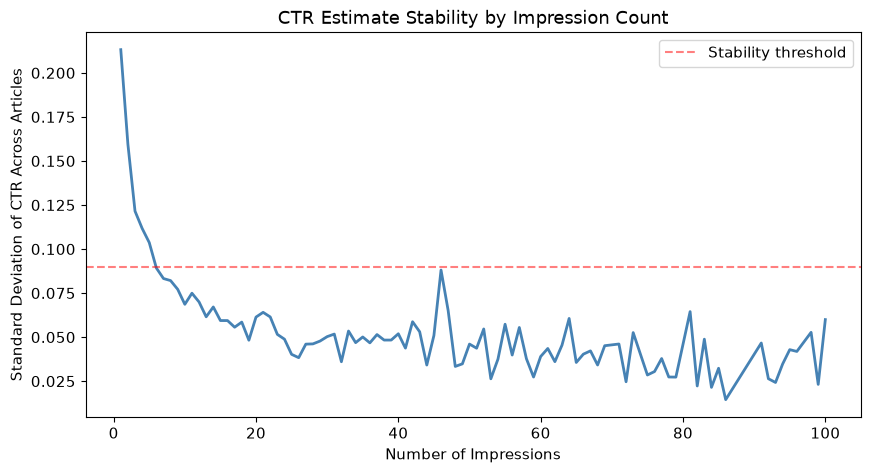

In [28]:
article_stats = impression_items.groupby('news_id').agg(
    impressions=('clicked', 'count'),
    clicks=('clicked', 'sum')
).reset_index()
article_stats['ctr'] = article_stats['clicks'] / article_stats['impressions']

# Group articles by their impression count and measure CTR variance
variance_by_count = []
for n in range(1, 101):
    subset = article_stats[article_stats['impressions'] == n]
    if len(subset) >= 10:  # need enough articles to measure variance meaningfully
        variance_by_count.append({
            'impression_count': n,
            'num_articles': len(subset),
            'ctr_std': subset['ctr'].std(),
            'ctr_mean': subset['ctr'].mean()
        })

var_df = pd.DataFrame(variance_by_count)

# Plot it
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(var_df['impression_count'], var_df['ctr_std'], color='steelblue', linewidth=2)
ax.set_xlabel('Number of Impressions')
ax.set_ylabel('Standard Deviation of CTR Across Articles')
ax.set_title('CTR Estimate Stability by Impression Count')
ax.axhline(y=var_df['ctr_std'].iloc[-1] * 1.5, color='red', linestyle='--', 
           alpha=0.5, label='Stability threshold')
ax.legend()
plt.show()

Floor CTR std (50+ impressions): 0.0390
  2.0x floor (0.0780): stable from ~9.0 impressions
  1.75x floor (0.0682): stable from ~13.0 impressions
  1.5x floor (0.0585): stable from ~17.0 impressions
  1.0x floor (0.0390): stable from ~58.0 impressions


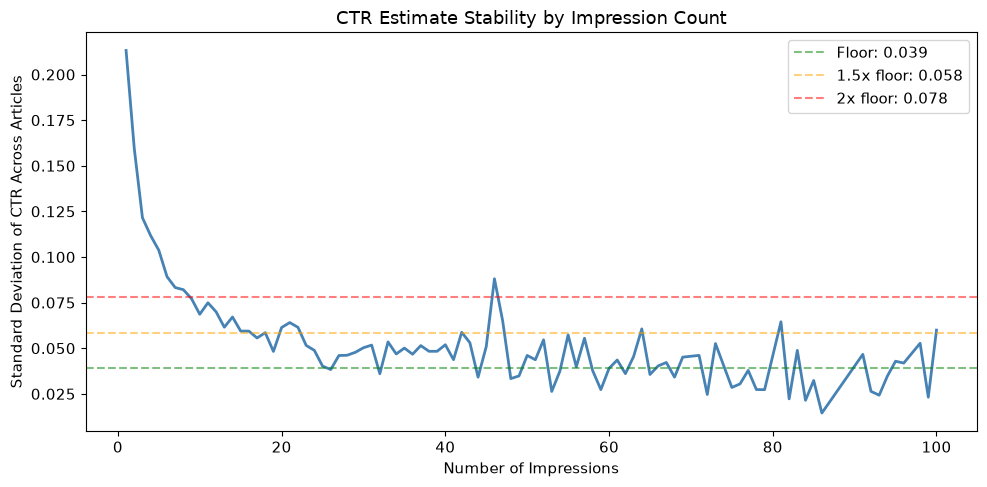

In [29]:
# Compute the "floor" — average std deviation for articles with 50+ impressions
floor_std = var_df[var_df['impression_count'] >= 50]['ctr_std'].median()
print(f"Floor CTR std (50+ impressions): {floor_std:.4f}")

# Find where the curve first drops to within 1.5x of the floor and stays there
multipliers = [2.0, 1.75, 1.5, 1.0]
for mult in multipliers:
    threshold_val = floor_std * mult
    # Find first impression count where std drops below this 
    # and the average of the next 5 points also stays below
    for i in range(len(var_df) - 5):
        current = var_df.iloc[i]['ctr_std']
        next_5_avg = var_df.iloc[i:i+5]['ctr_std'].mean()
        if current < threshold_val and next_5_avg < threshold_val:
            imp_count = var_df.iloc[i]['impression_count']
            print(f"  {mult}x floor ({threshold_val:.4f}): stable from ~{imp_count} impressions")
            break

# Also plot it more clearly
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(var_df['impression_count'], var_df['ctr_std'], color='steelblue', linewidth=2)
ax.axhline(y=floor_std, color='green', linestyle='--', alpha=0.5, label=f'Floor: {floor_std:.3f}')
ax.axhline(y=floor_std * 1.5, color='orange', linestyle='--', alpha=0.5, label=f'1.5x floor: {floor_std*1.5:.3f}')
ax.axhline(y=floor_std * 2.0, color='red', linestyle='--', alpha=0.5, label=f'2x floor: {floor_std*2.0:.3f}')
ax.set_xlabel('Number of Impressions')
ax.set_ylabel('Standard Deviation of CTR Across Articles')
ax.set_title('CTR Estimate Stability by Impression Count')
ax.legend()
plt.tight_layout()
plt.savefig('ctr_stability_threshold.png', bbox_inches='tight')
plt.show()

In [30]:
floor_std = var_df[var_df['impression_count'] >= 50]['ctr_std'].median()
std_at_5 = var_df[var_df['impression_count'] == 10]['ctr_std'].values[0]

multiplier = std_at_5 / floor_std
print(f"Floor std (50+ impressions): {floor_std:.4f}")
print(f"Std at 5 impressions: {std_at_5:.4f}")
print(f"5 impressions = {multiplier:.1f}x the floor")

Floor std (50+ impressions): 0.0390
Std at 5 impressions: 0.0686
5 impressions = 1.8x the floor


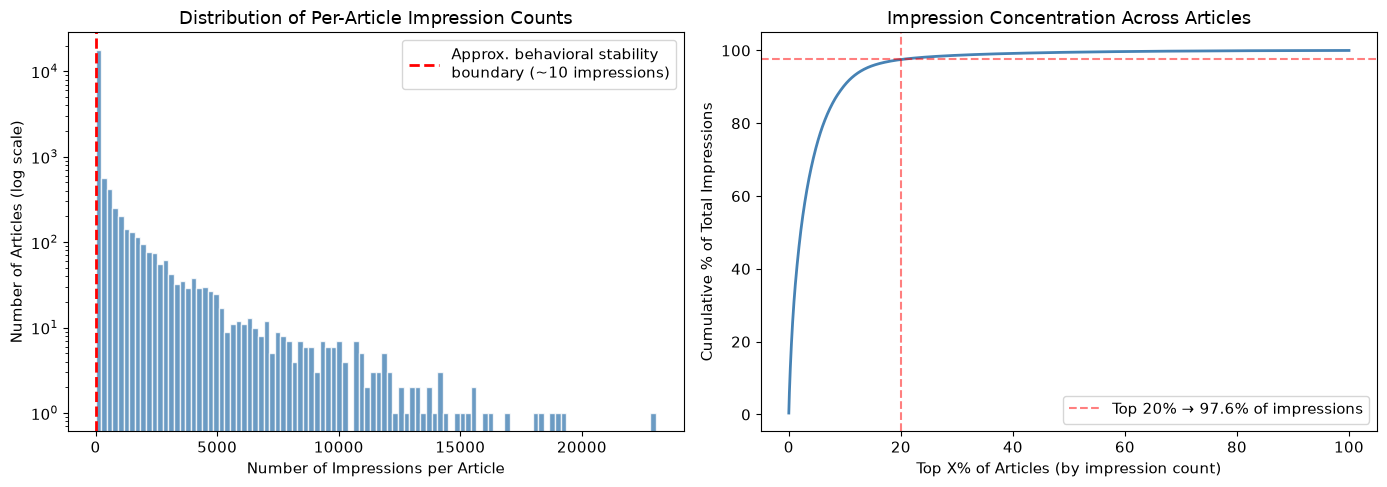

In [31]:
article_impressions = impression_items.groupby('news_id').size().reset_index(name='impression_count')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(article_impressions['impression_count'], bins=100,
             color='steelblue', edgecolor='white', alpha=0.8)
axes[0].set_yscale('log')
axes[0].axvline(10, color='red', linestyle='--', linewidth=2,
                label='Approx. behavioral stability\nboundary (~10 impressions)')
axes[0].set_xlabel('Number of Impressions per Article')
axes[0].set_ylabel('Number of Articles (log scale)')
axes[0].set_title('Distribution of Per-Article Impression Counts')
axes[0].legend()

sorted_counts = article_impressions['impression_count'].sort_values(ascending=False).values
cumulative_share = np.cumsum(sorted_counts) / sorted_counts.sum()
article_pct = np.arange(1, len(sorted_counts) + 1) / len(sorted_counts) * 100

axes[1].plot(article_pct, cumulative_share * 100, color='steelblue', linewidth=2)
axes[1].axhline(97.6, color='red', linestyle='--', alpha=0.5,
                label='Top 20% → 97.6% of impressions')
axes[1].axvline(20, color='red', linestyle='--', alpha=0.5)
axes[1].set_xlabel('Top X% of Articles (by impression count)')
axes[1].set_ylabel('Cumulative % of Total Impressions')
axes[1].set_title('Impression Concentration Across Articles')
axes[1].legend()

plt.tight_layout()
plt.savefig('exposure_concentration_v2.png', bbox_inches='tight')
plt.show()

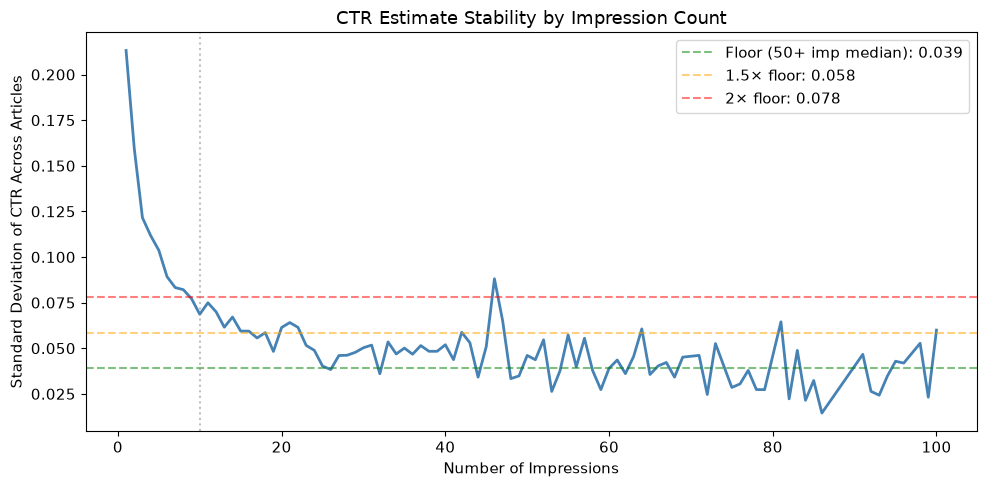

In [32]:
fig, ax = plt.subplots(figsize=(10, 5))

floor_std = var_df[var_df['impression_count'] >= 50]['ctr_std'].median()

ax.plot(var_df['impression_count'], var_df['ctr_std'], color='steelblue', linewidth=2)
ax.axhline(y=floor_std, color='green', linestyle='--', alpha=0.5,
           label=f'Floor (50+ imp median): {floor_std:.3f}')
ax.axhline(y=floor_std * 1.5, color='orange', linestyle='--', alpha=0.5,
           label=f'1.5× floor: {floor_std*1.5:.3f}')
ax.axhline(y=floor_std * 2.0, color='red', linestyle='--', alpha=0.5,
           label=f'2× floor: {floor_std*2.0:.3f}')
ax.axvline(x=10, color='gray', linestyle=':', alpha=0.5)
ax.set_xlabel('Number of Impressions')
ax.set_ylabel('Standard Deviation of CTR Across Articles')
ax.set_title('CTR Estimate Stability by Impression Count')
ax.legend()

plt.tight_layout()
plt.savefig('ctr_stability_analysis.png', bbox_inches='tight')
plt.show()

In [33]:
# Make sure article_imp_counts exists
article_imp_counts = impression_items.groupby('news_id').size().reset_index(name='imp_count')

for threshold in [5, 10, 15, 20]:
    cold = article_imp_counts[article_imp_counts['imp_count'] <= threshold]
    cold_ids = set(cold['news_id'])
    cold_pairs = impression_items[impression_items['news_id'].isin(cold_ids)]
    
    print(f"Threshold <= {threshold}:")
    print(f"  Cold articles: {len(cold):,} / {len(article_imp_counts):,} "
          f"({len(cold)/len(article_imp_counts):.1%})")
    print(f"  Cold impression pairs: {len(cold_pairs):,} / {len(impression_items):,} "
          f"({len(cold_pairs)/len(impression_items):.1%})")
    print()

Threshold <= 5:
  Cold articles: 8,958 / 20,288 (44.2%)
  Cold impression pairs: 21,319 / 5,843,444 (0.4%)

Threshold <= 10:
  Cold articles: 11,902 / 20,288 (58.7%)
  Cold impression pairs: 43,937 / 5,843,444 (0.8%)

Threshold <= 15:
  Cold articles: 13,354 / 20,288 (65.8%)
  Cold impression pairs: 62,531 / 5,843,444 (1.1%)

Threshold <= 20:
  Cold articles: 14,262 / 20,288 (70.3%)
  Cold impression pairs: 78,741 / 5,843,444 (1.3%)



In [34]:
# Run this on whichever split you're using (or both to compare)
# Make sure impression_items is built from the correct split

article_imp_counts = impression_items.groupby('news_id').size().sort_values(ascending=False)

total_impressions = article_imp_counts.sum()
total_articles = len(article_imp_counts)

# Cumulative share at different percentiles
for pct in [1, 5, 10, 20]:
    top_n = int(np.ceil(total_articles * pct / 100))
    top_share = article_imp_counts.iloc[:top_n].sum() / total_impressions
    print(f"Top {pct:>2d}% of articles ({top_n:,} articles) capture "
          f"{top_share:.1%} of all impressions")

# Also check the bottom 80%
bottom_80_n = total_articles - int(np.ceil(total_articles * 20 / 100))
bottom_80_share = article_imp_counts.iloc[-bottom_80_n:].sum() / total_impressions
print(f"\nBottom 80% of articles ({bottom_80_n:,} articles) share "
      f"{bottom_80_share:.1%} of all impressions")

print(f"\nTotal articles in impressions: {total_articles:,}")
print(f"Total impression-article pairs: {total_impressions:,}")

Top  1% of articles (203 articles) capture 32.5% of all impressions
Top  5% of articles (1,015 articles) capture 74.1% of all impressions
Top 10% of articles (2,029 articles) capture 90.5% of all impressions
Top 20% of articles (4,058 articles) capture 97.5% of all impressions

Bottom 80% of articles (16,230 articles) share 2.5% of all impressions

Total articles in impressions: 20,288
Total impression-article pairs: 5,843,444


## 9. Summary of Key Findings

### Impression Slate Distribution

Each impression displays a variable number of candidate articles to the user. Across 156,965 impression records, the average slate length is 37.2 articles (median: 24, range: 2–299). The distribution is right-skewed: over half of impressions show 24 or fewer articles, but a long tail extends past 150, pulling the mean well above the median. The 10th percentile is just 4 articles while the 90th percentile is 91, indicating substantial variation in how much content each user is exposed to per visit.

### Position Bias (revised: a slate-length effect, not position bias; see the note in section 3.2)

Click-through rate exhibits a clear position effect. Positions 1 and 2 have nearly identical CTR (~10.8%), suggesting both slots receive equivalent visual prominence (likely above the fold). CTR then declines steadily: position 5 drops to 6.58%, position 10 to 5.04%, and by position 20 it falls below 3%. Beyond position 50, CTR stabilizes around 1.5–2%.

The top 3 display positions have a combined CTR of 9.94%, which is 2.8× higher than positions 4 and beyond (3.54%). This indicates meaningful position bias: articles placed higher receive more clicks partly due to visibility rather than purely due to user preference. For modeling, this means that non-clicks on articles displayed at high positions (e.g., positions beyond 20) are weaker negative signals — the user may not have scrolled far enough to see them. Position debiasing during model training could help separate genuine preference from positional effects.

### Interaction Funnel & Class Imbalance

Of 5,843,444 total article-impression pairs, only 236,344 (4.04%) were clicked, producing a positive-to-negative ratio of approximately 1:24. Every impression in the training set contains at least one click, indicating the dataset has been pre-filtered to exclude zero-engagement impressions.

Among active impressions, 72.6% contain exactly one click and 94.8% contain three or fewer. The average is 1.51 clicks per impression with a maximum of 35. Users typically click a single article per visit — multi-click browsing behavior is relatively uncommon.

CTR varies inversely with slate length: short slates (1–5 articles) have a 37.09% CTR but only ~1 click on average, while long slates (100+ articles) have a 1.98% CTR but ~2.6 clicks. Longer sessions yield more total engagement but a lower proportion of clicks per article shown.

### Feedback Semantics

Three types of user-article feedback exist in the dataset:

Clicked (Positive): On average, each user clicks 4.7 articles.
Shown but not clicked (Explicit Negative): On average, each user is shown but ignores 95 articles.
Never shown (Unknown): On average, 51,182 articles are never displayed to a given user.

Each user sees only 0.19% of the full 51,282-article catalog. This extreme sparsity means that randomly sampling negative examples from the unseen pool produces "easy" negatives — articles with no topical relevance to the user. In contrast, the ~95 impression negatives per user are "hard" negatives: articles the platform's ranking algorithm already deemed relevant enough to display, but which the user chose not to click. Training models on impression negatives rather than random negatives forces the model to learn finer preference distinctions.

### Category-Level Click Patterns

Music (5.94% CTR), TV (5.90%), and weather (5.17%) are the most engaging categories, while travel (2.64%), autos (2.74%), and food & drink (2.95%) are least engaging. However, volume and engagement are not aligned: "news" dominates exposure with 1.59 million impressions (more than double any other category) yet achieves only a mid-table CTR of 4.36%, suggesting the platform over-serves general news relative to user engagement. Niche categories like music and TV have higher engagement rates but receive less exposure volume. This mismatch between what is shown and what users engage with could inform category-aware recommendation strategies.